# Mini Diffusion Model: DDPM → DDIM on MNIST

Implements a small DDPM (Ho et al., 2020) with a CNN noise predictor, then changes only the **sampler** to get DDIM (Song et al., 2021).

**Config:** T = 100, β linear from 1e-4 to **0.2** (see note below), batch size 128, 50 epochs.

> **Note on β_end.** The assignment suggests β_end = 0.02. With only T = 100 steps that gives ᾱ_T ≈ 0.36, so x_T still carries ~60% of the signal and is *not* N(0, I). Sampling starts from pure Gaussian noise, so the sampler begins off-distribution; in our first run with 0.02 the generated samples were digit-like squiggles rather than digits (training loss plateaued near 0.059). We therefore scale β_end to 0.2 so that ᾱ_T ≈ 0 while keeping T = 100 and the linear schedule. Set `BETA_END = 0.02` to reproduce the original config.

| Section | Task |
|---|---|
| 1 | (a) Forward diffusion + visualization |
| 2 | (b) CNN noise predictor + training loss |
| 3 | (c) DDPM reverse sampling |
| 4 | (d) DDIM sampling, comparison, discussion |

In [2]:
import copy, math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

# ---- configuration ----
T = 100
BETA_START, BETA_END = 1e-4, 0.02
BATCH_SIZE = 128
EPOCHS = 50
LR = 2e-4

# ---- noise schedule (index t = 0..T-1 corresponds to the paper's t = 1..T) ----
betas      = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas     = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)          # \bar{alpha}_t
print(f"alpha_bar[0]={alpha_bars[0]:.4f}  alpha_bar[T-1]={alpha_bars[-1]:.6f}  (should be ~0 so x_T ~ N(0,I))")

device: cuda
alpha_bar[0]=0.9999  alpha_bar[T-1]=0.363563  (should be ~0 so x_T ~ N(0,I))


In [3]:
# MNIST scaled to [-1, 1]
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_ds = datasets.MNIST("./data", train=True, download=True, transform=tfm)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=2, pin_memory=True)
print(len(train_ds), "training images;", len(train_loader), "batches/epoch")

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 486kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.41MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.73MB/s]

60000 training images; 468 batches/epoch


## (a) Forward diffusion

Closed form of the forward process:

$$q(x_t \mid x_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)\mathbf{I}\big) \quad\Longleftrightarrow\quad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\ \ \epsilon\sim\mathcal{N}(0,\mathbf{I})$$

with $\alpha_t = 1-\beta_t$ and $\bar\alpha_t=\prod_{s\le t}\alpha_s$.

In [4]:
def extract(a, t, x_shape):
    """Gather a[t] and reshape to broadcast over an image batch."""
    return a[t].view(-1, *([1] * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    """Forward diffusion: sample x_t ~ q(x_t | x_0)."""
    if noise is None:
        noise = torch.randn_like(x0)
    return extract(alpha_bars, t, x0.shape).sqrt() * x0 + extract(1 - alpha_bars, t, x0.shape).sqrt() * noise

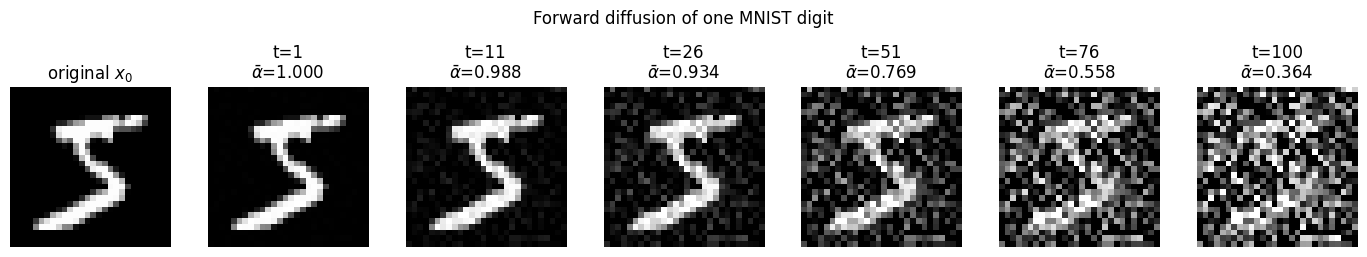

In [5]:
x0, y0 = train_ds[0]
x0 = x0.unsqueeze(0).to(device)
show_t = [0, 10, 25, 50, 75, 99]          # 0-indexed timesteps (paper's t = 1, 11, 26, 51, 76, 100)

torch.manual_seed(1)
eps = torch.randn_like(x0)                 # same noise at every t so the progression is comparable
fig, axes = plt.subplots(1, len(show_t) + 1, figsize=(2 * (len(show_t) + 1), 2.4))
axes[0].imshow(x0[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1); axes[0].set_title("original $x_0$"); axes[0].axis("off")
for ax, t in zip(axes[1:], show_t):
    xt = q_sample(x0, torch.tensor([t], device=device), eps)
    ax.imshow(xt[0, 0].cpu().clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t={t+1}\n$\\bar\\alpha$={alpha_bars[t]:.3f}"); ax.axis("off")
plt.suptitle("Forward diffusion of one MNIST digit", y=1.05); plt.tight_layout(); plt.show()

## (b) Train a mini DDPM

**Network** — a small U-Net-style CNN with **8 convolutional layers**, SiLU nonlinearities (a smooth ReLU variant), GroupNorm, two down-sampling and two up-sampling stages for a large receptive field, and skip connections. The timestep is conditioned through a sinusoidal embedding → MLP, which is projected and *added* as a per-channel bias inside each conv block. The output has the same shape as the input (1×28×28). Weights are tracked with an exponential moving average (EMA), which is used for sampling; this is standard in diffusion models and noticeably cleans up samples.

**Loss** (simple DDPM objective):

$$L = \mathbb{E}_{x_0,\,t,\,\epsilon}\Big[\ \big\|\epsilon - \epsilon_\theta(x_t, t)\big\|^2\ \Big]$$

In [6]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 4), nn.SiLU(), nn.Linear(dim * 4, dim * 4))
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None]
        return self.mlp(torch.cat([args.sin(), args.cos()], dim=-1))

class ConvBlock(nn.Module):
    """conv -> GroupNorm -> (+ time bias) -> SiLU"""
    def __init__(self, cin, cout, temb_dim, stride=1):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, stride=stride, padding=1)
        self.norm = nn.GroupNorm(8, cout)
        self.t_proj = nn.Linear(temb_dim, cout)
    def forward(self, x, temb):
        h = self.norm(self.conv(x))
        h = h + self.t_proj(temb)[:, :, None, None]
        return F.silu(h)

class NoisePredictor(nn.Module):
    """8 conv layers (U-Net style): 28x28 -> 14x14 -> 7x7 -> back up, with skip connections."""
    def __init__(self, ch=64, tdim=32):
        super().__init__()
        self.temb = TimeEmbedding(tdim)
        td = tdim * 4
        self.c1 = ConvBlock(1,           ch,     td)                 # 28x28
        self.c2 = ConvBlock(ch,          ch * 2, td, stride=2)        # 14x14
        self.c3 = ConvBlock(ch * 2,      ch * 2, td)                  # 14x14
        self.c4 = ConvBlock(ch * 2,      ch * 4, td, stride=2)        # 7x7
        self.c5 = ConvBlock(ch * 4,      ch * 4, td)                  # 7x7
        self.c6 = ConvBlock(ch * 4 + ch * 2, ch * 2, td)              # 14x14 (+skip from c3)
        self.c7 = ConvBlock(ch * 2 + ch,     ch,     td)              # 28x28 (+skip from c1)
        self.c8 = nn.Conv2d(ch, 1, 3, padding=1)                      # output conv: no norm / activation
    def forward(self, x, t):
        e = self.temb(t)
        h1 = self.c1(x, e)                                            # 28x28
        h2 = self.c3(self.c2(h1, e), e)                               # 14x14
        h  = self.c5(self.c4(h2, e), e)                               # 7x7
        h  = F.interpolate(h, scale_factor=2, mode="nearest")
        h  = self.c6(torch.cat([h, h2], dim=1), e)                    # 14x14
        h  = F.interpolate(h, scale_factor=2, mode="nearest")
        h  = self.c7(torch.cat([h, h1], dim=1), e)                    # 28x28
        return self.c8(h)

model = NoisePredictor().to(device)
n_convs = sum(isinstance(m, nn.Conv2d) for m in model.modules())
print(f"conv layers: {n_convs} | parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")
assert model(torch.randn(4, 1, 28, 28, device=device), torch.randint(0, T, (4,), device=device)).shape == (4, 1, 28, 28)

conv layers: 8 | parameters: 1.82M


In [7]:
opt = torch.optim.Adam(model.parameters(), lr=LR)
ema = copy.deepcopy(model).eval()
EMA_DECAY = 0.999
losses, epoch_losses = [], []

t0 = time.time()
for epoch in range(EPOCHS):
    model.train(); running = 0.0
    for x, _ in train_loader:
        x = x.to(device, non_blocking=True)
        t = torch.randint(0, T, (x.size(0),), device=device)     # uniform random timestep per sample
        eps = torch.randn_like(x)
        loss = F.mse_loss(model(q_sample(x, t, eps), t), eps)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        with torch.no_grad():
            for pe, p in zip(ema.parameters(), model.parameters()): pe.lerp_(p, 1 - EMA_DECAY)
            for be, b in zip(ema.buffers(), model.buffers()): be.copy_(b)
        losses.append(loss.item()); running += loss.item()
    epoch_losses.append(running / len(train_loader))
    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch+1:3d}/{EPOCHS}  loss {epoch_losses[-1]:.4f}  ({time.time()-t0:.0f}s)")

torch.save({"model": model.state_dict(), "ema": ema.state_dict()}, "mini_ddpm.pt")
model.load_state_dict(ema.state_dict()); model.eval()      # sample with the EMA weights
print("sampling with EMA weights")

epoch   1/50  loss 0.1650  (24s)
epoch   6/50  loss 0.0685  (148s)
epoch  11/50  loss 0.0627  (281s)
epoch  16/50  loss 0.0600  (412s)
epoch  21/50  loss 0.0584  (544s)
epoch  26/50  loss 0.0572  (676s)
epoch  31/50  loss 0.0564  (809s)
epoch  36/50  loss 0.0560  (941s)
epoch  41/50  loss 0.0556  (1073s)
epoch  46/50  loss 0.0551  (1205s)
epoch  50/50  loss 0.0548  (1311s)
sampling with EMA weights


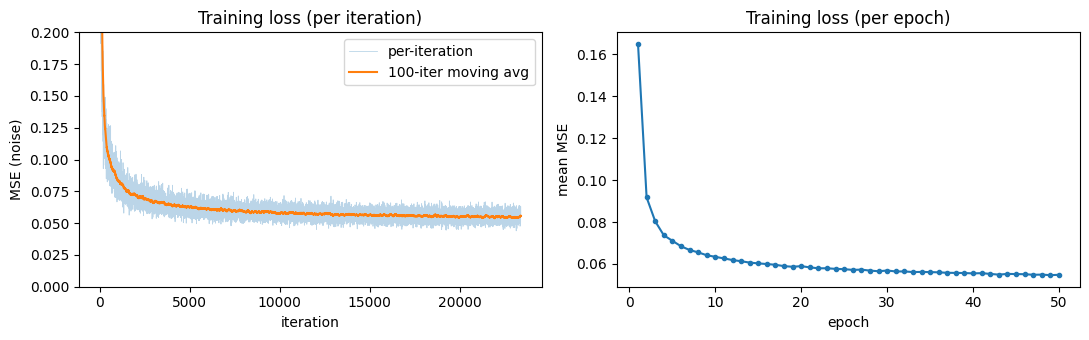

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses, alpha=0.3, lw=0.6, label="per-iteration")
k = 100; sm = np.convolve(losses, np.ones(k) / k, mode="valid")
ax[0].plot(np.arange(k - 1, len(losses)), sm, lw=1.5, label=f"{k}-iter moving avg")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("MSE (noise)"); ax[0].set_title("Training loss (per iteration)"); ax[0].legend(); ax[0].set_ylim(0, min(0.2, max(sm) * 3))
ax[1].plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o", ms=3)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean MSE"); ax[1].set_title("Training loss (per epoch)")
plt.tight_layout(); plt.show()

## (c) DDPM sampling (ancestral, 100 steps)

Start from $x_T\sim\mathcal N(0,I)$ and iterate for $t=T,\dots,1$:

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\Big(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big)+\sigma_t z,\qquad z\sim\mathcal N(0,I)\ (z=0\text{ at the last step}),\ \ \sigma_t^2=\beta_t$$

In [9]:
@torch.no_grad()
def ddpm_sample(model, n, noise=None, seed=None):
    model.eval()
    g = torch.Generator(device=device)
    if seed is not None: g.manual_seed(seed)
    x = noise.clone() if noise is not None else torch.randn(n, 1, 28, 28, device=device, generator=g)
    for t in reversed(range(T)):
        tt = torch.full((x.size(0),), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        mean = (x - betas[t] / (1 - alpha_bars[t]).sqrt() * eps) / alphas[t].sqrt()
        z = torch.randn(x.shape, device=device, generator=g) if t > 0 else torch.zeros_like(x)
        x = mean + betas[t].sqrt() * z                       # sigma_t^2 = beta_t
    return x.clamp(-1, 1)

## (d) DDIM sampling

DDIM keeps the **same trained network**; only the reverse update changes. Pick a sub-sequence of timesteps $\tau_1<\dots<\tau_S$ and, at each step:

$$\hat x_0=\frac{x_{\tau_i}-\sqrt{1-\bar\alpha_{\tau_i}}\,\epsilon_\theta(x_{\tau_i},\tau_i)}{\sqrt{\bar\alpha_{\tau_i}}},\qquad
x_{\tau_{i-1}}=\sqrt{\bar\alpha_{\tau_{i-1}}}\,\hat x_0+\sqrt{1-\bar\alpha_{\tau_{i-1}}-\sigma^2}\;\epsilon_\theta+\sigma z$$

$$\sigma=\eta\sqrt{\tfrac{1-\bar\alpha_{\tau_{i-1}}}{1-\bar\alpha_{\tau_i}}}\sqrt{1-\tfrac{\bar\alpha_{\tau_i}}{\bar\alpha_{\tau_{i-1}}}}$$

With **η = 0** the sampler is fully deterministic (pure DDIM). With η = 1 and all T steps it recovers the DDPM update. We clip $\hat x_0$ to $[-1,1]$ for stability at few steps.

In [10]:
@torch.no_grad()
def ddim_sample(model, n, steps, eta=0.0, noise=None, seed=None, clip_x0=True):
    model.eval()
    g = torch.Generator(device=device)
    if seed is not None: g.manual_seed(seed)
    x = noise.clone() if noise is not None else torch.randn(n, 1, 28, 28, device=device, generator=g)
    taus = np.unique(np.linspace(0, T - 1, steps).round().astype(int))[::-1]    # descending, always includes T-1 and 0
    for i, t in enumerate(taus):
        tt = torch.full((x.size(0),), int(t), device=device, dtype=torch.long)
        eps = model(x, tt)
        ab_t = alpha_bars[t]
        ab_prev = alpha_bars[taus[i + 1]] if i + 1 < len(taus) else torch.tensor(1.0, device=device)
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        if clip_x0: x0_hat = x0_hat.clamp(-1, 1)
        sigma = eta * ((1 - ab_prev) / (1 - ab_t)).sqrt() * (1 - ab_t / ab_prev).sqrt()
        dir_xt = (1 - ab_prev - sigma ** 2).clamp(min=0).sqrt() * eps
        z = torch.randn(x.shape, device=device, generator=g) if eta > 0 else 0.0
        x = ab_prev.sqrt() * x0_hat + dir_xt + sigma * z
    return x.clamp(-1, 1)

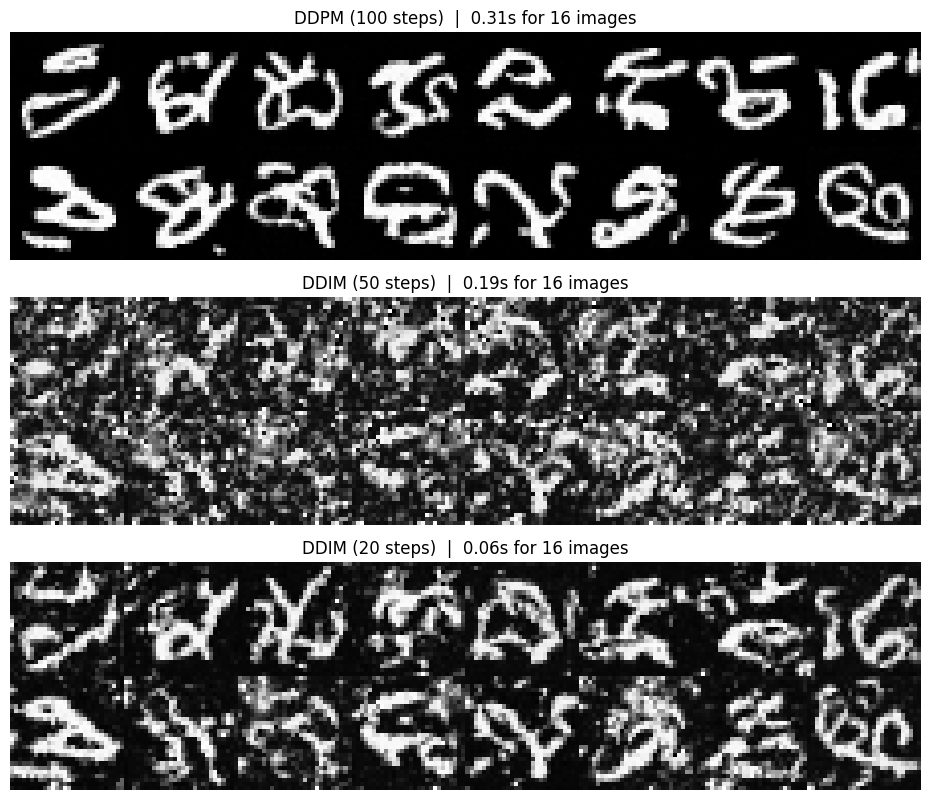

In [11]:
N = 16
shared_noise = torch.randn(N, 1, 28, 28, device=device, generator=torch.Generator(device=device).manual_seed(123))

def timed(fn):
    if device.type == "cuda": torch.cuda.synchronize()
    s = time.time(); out = fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return out, time.time() - s

samples = {}
samples["DDPM (100 steps)"], t_ddpm = timed(lambda: ddpm_sample(model, N, noise=shared_noise, seed=7))
samples["DDIM (50 steps)"],  t_d50  = timed(lambda: ddim_sample(model, N, 50, noise=shared_noise))
samples["DDIM (20 steps)"],  t_d20  = timed(lambda: ddim_sample(model, N, 20, noise=shared_noise))
times = {"DDPM (100 steps)": t_ddpm, "DDIM (50 steps)": t_d50, "DDIM (20 steps)": t_d20}

def grid(x, nrow=8):
    x = (x.cpu() + 1) / 2
    rows = [torch.cat(list(x[i:i + nrow]), dim=-1)[0] for i in range(0, len(x), nrow)]
    return torch.cat(rows, dim=0)

fig, axes = plt.subplots(3, 1, figsize=(10, 3 * 2.7))
for ax, (name, x) in zip(axes, samples.items()):
    ax.imshow(grid(x), cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"{name}  |  {times[name]:.2f}s for {N} images")
plt.tight_layout(); plt.show()

**Same starting noise, different samplers.** All three rows start from the identical $x_T$. DDIM is deterministic, so the same noise always maps to the same image; DDPM injects fresh noise at every step.

DDIM 50 vs DDIM 50 (same noise, rerun):    MSE = 0.000000   <- deterministic
DDPM vs DDPM   (same x_T, diff. seeds):    MSE = 0.371435   <- stochastic
DDIM 50 steps vs DDIM 100-step reference:  MSE = 0.024734
DDIM 20 steps vs DDIM 100-step reference:  MSE = 0.215921


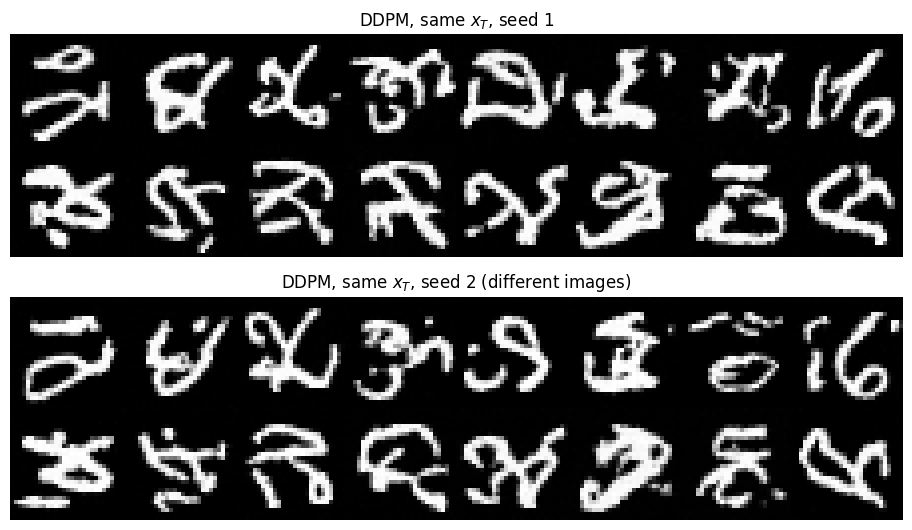

In [12]:
# Determinism check + how close the few-step DDIM results are to the 100-step DDIM result
a = ddim_sample(model, N, 50, noise=shared_noise); b = ddim_sample(model, N, 50, noise=shared_noise)
c = ddpm_sample(model, N, noise=shared_noise, seed=1); d = ddpm_sample(model, N, noise=shared_noise, seed=2)
ref = ddim_sample(model, N, T, noise=shared_noise)                   # DDIM with all 100 steps as reference
mse = lambda u, v: F.mse_loss(u, v).item()
print(f"DDIM 50 vs DDIM 50 (same noise, rerun):    MSE = {mse(a, b):.6f}   <- deterministic")
print(f"DDPM vs DDPM   (same x_T, diff. seeds):    MSE = {mse(c, d):.6f}   <- stochastic")
print(f"DDIM 50 steps vs DDIM 100-step reference:  MSE = {mse(a, ref):.6f}")
print(f"DDIM 20 steps vs DDIM 100-step reference:  MSE = {mse(samples['DDIM (20 steps)'], ref):.6f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 2 * 2.7))
axes[0].imshow(grid(c), cmap="gray", vmin=0, vmax=1); axes[0].axis("off"); axes[0].set_title("DDPM, same $x_T$, seed 1")
axes[1].imshow(grid(d), cmap="gray", vmin=0, vmax=1); axes[1].axis("off"); axes[1].set_title("DDPM, same $x_T$, seed 2 (different images)")
plt.tight_layout(); plt.show()

## Discussion: DDPM vs DDIM

**Same model, different sampler.** DDPM and DDIM use the identical trained $\epsilon_\theta$. The training objective only constrains the marginals $q(x_t\mid x_0)$, and many reverse processes share them. DDPM uses the Markovian one with $\sigma_t^2=\beta_t$; DDIM (η = 0) uses a non-Markovian, deterministic one.

**Stochasticity.** DDPM adds fresh Gaussian noise at every step, so one starting $x_T$ can lead to many different digits (see the two DDPM rows above). DDIM with η = 0 is deterministic: the same $x_T$ always gives the same image, making $x_T$ a latent code. That also allows meaningful interpolation and encoding/inversion, which DDPM does not.

**Speed.** Sampling cost is proportional to the number of network evaluations: DDPM needs all 100, DDIM needs only 50 or 20, which is roughly 2× and 5× fewer evaluations. The timings above reflect this.

**Quality vs. steps.** DDPM must take small steps because each step assumes the reverse conditional is approximately Gaussian, so skipping steps breaks it. DDIM instead takes each long jump along a deterministic path by predicting $\hat x_0$ and re-noising it to the target level, so it stays usable with far fewer steps. Compare the rows above: DDIM-50 should stay close to the full 100-step result, while DDIM-20 trades some fine detail for speed because each step makes a larger discretization jump. The MSE numbers against the 100-step DDIM reference quantify this gap. This is the usual speed/quality trade-off, and DDIM degrades much more gracefully than skipping steps in DDPM would.

**Schedule matters.** Sample quality depends on x_T actually being close to N(0, I). With β_end = 0.02 and T = 100, ᾱ_T ≈ 0.36 and both samplers produced poor samples because they start from the wrong distribution; with ᾱ_T ≈ 0 (β_end = 0.2) this mismatch disappears.

**Takeaway.** Use DDPM when sample diversity from a stochastic process matters and compute is cheap; use DDIM when you want fast sampling or a deterministic noise→image mapping. Setting η between 0 and 1 interpolates between the two.